In [25]:
# ============================================================
# Multidimensional Linear Regression Models for xG Prediction
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import itertools

In [26]:


# ---------------------------------------
# Load Dataset
# ---------------------------------------

PATH = "../../statsbomb_pipeline/data/processed/player/player_season_model_dataset.csv"

df = pd.read_csv(PATH)

# Filter to players with enough minutes (consistent with PCA / earlier analysis)
MIN_MINUTES = 900
model_df = df[df["minutes_played_total"] >= MIN_MINUTES].copy()

# Target variable
target_col = "xg_total"

# ---------------------------------------
# Define Predictor Sets
# ---------------------------------------

# Candidate predictors we want to consider
candidate_features = [
    "minutes_played_total",
    "matches_played",
    "xThreat_total",
    "xThreat_pass_total",
    "xThreat_carry_total",
    "xThreat_per90",
    "xThreat_pass_per90",
    "xThreat_carry_per90",
]

# Make sure no missing data
subset_cols = [target_col] + candidate_features
subset_df = model_df.dropna(subset=subset_cols).copy()
print("Sample size after dropping NA:", subset_df.shape[0])

# One train/test split used for ALL models
X_full = subset_df[candidate_features].values
y = subset_df[target_col].values

X_train, X_test, y_train, y_test = train_test_split(
    X_full, y, test_size=0.2, random_state=42
)

print("Train size:", X_train.shape[0], "Test size:", X_test.shape[0])

Sample size after dropping NA: 324
Train size: 259 Test size: 65


In [27]:
def fit_and_evaluate_lr(X_train, X_test, y_train, y_test, feature_names, model_name="Model"):
    """Fit a linear regression model and print/evaluate metrics."""
    lr = LinearRegression()
    lr.fit(X_train, y_train)

    y_pred_train = lr.predict(X_train)
    y_pred_test = lr.predict(X_test)

    # Metrics
    r2_train = r2_score(y_train, y_pred_train)
    r2_test = r2_score(y_test, y_pred_test)

    mse_train = mean_squared_error(y_train, y_pred_train)
    mse_test = mean_squared_error(y_test, y_pred_test)


    rmse_train = mse_train ** 0.5
    rmse_test = mse_test ** 0.5

    print(f"=== {model_name} ===")
    print(f"R^2 (train):  {r2_train:.4f}")
    print(f"R^2 (test):   {r2_test:.4f}")
    print(f"MSE (train):  {mse_train:.4f}")
    print(f"MSE (test):   {mse_test:.4f}")
    print(f"RMSE (train): {rmse_train:.4f}")
    print(f"RMSE (test):  {rmse_test:.4f}")
    print()

    coef_table = pd.DataFrame({
        "feature": feature_names,
        "coefficient": lr.coef_
    })

    intercept = lr.intercept_

    return {
        "model": lr,
        "coef_table": coef_table,
        "intercept": intercept,
        "r2_train": r2_train,
        "r2_test": r2_test,
        "mse_train": mse_train,
        "mse_test": mse_test,
        "rmse_train": rmse_train,
        "rmse_test": rmse_test,
        "y_pred_test": y_pred_test,
    }


In [28]:
def evaluate_subset(feature_indices):
    """Fit linear regression on a subset of columns given by indices."""
    X_train_sub = X_train[:, feature_indices]
    X_test_sub = X_test[:, feature_indices]

    lr = LinearRegression()
    lr.fit(X_train_sub, y_train)

    y_pred_train = lr.predict(X_train_sub)
    y_pred_test = lr.predict(X_test_sub)

    r2_train = r2_score(y_train, y_pred_train)
    r2_test = r2_score(y_test, y_pred_test)

    mse_train = mean_squared_error(y_train, y_pred_train)
    mse_test = mean_squared_error(y_test, y_pred_test)

    rmse_train = mse_train ** 0.5
    rmse_test = mse_test ** 0.5

    return r2_train, r2_test, mse_train, mse_test, rmse_train, rmse_test

results = []

n_features = len(candidate_features)
feature_indices_list = list(range(n_features))

# Try all non-empty subsets
for r in range(1, n_features + 1):
    for combo in itertools.combinations(feature_indices_list, r):
        r2_train, r2_test, mse_train, mse_test, rmse_train, rmse_test = evaluate_subset(combo)
        used_features = [candidate_features[i] for i in combo]
        results.append({
            "num_features": len(used_features),
            "features": used_features,
            "R2_train": r2_train,
            "R2_test": r2_test,
            "MSE_train": mse_train,
            "MSE_test": mse_test,
            "RMSE_train": rmse_train,
            "RMSE_test": rmse_test,
        })

subset_summary = pd.DataFrame(results)

# Sort by test R^2 descending (best generalization first)
subset_summary_sorted = subset_summary.sort_values("R2_test", ascending=False)
subset_summary_sorted.head(10)


,num_features,features,R2_train,R2_test,MSE_train,MSE_test,RMSE_train,RMSE_test
8,2,"[minutes_played_total, matches_played]",0.198247,0.161904,9.590756,8.310639,3.096895,2.882818
36,3,"[minutes_played_total, matches_played, xThreat...",0.198534,0.160956,9.587324,8.320033,3.096340,2.884447
39,3,"[minutes_played_total, matches_played, xThreat...",0.198916,0.158997,9.582748,8.339459,3.095601,2.887812
41,3,"[minutes_played_total, matches_played, xThreat...",0.207074,0.158208,9.485163,8.347282,3.079799,2.889166
94,4,"[minutes_played_total, matches_played, xThreat...",0.199460,0.155147,9.576242,8.377642,3.094550,2.894416
59,3,"[matches_played, xThreat_total, xThreat_per90]",0.149900,0.152999,10.169094,8.398938,3.188902,2.898092
96,4,"[minutes_played_total, matches_played, xThreat...",0.210297,0.152818,9.446607,8.400730,3.073533,2.898401
20,2,"[matches_played, xThreat_carry_per90]",0.148542,0.152434,10.185334,8.404538,3.191447,2.899058
37,3,"[minutes_played_total, matches_played, xThreat...",0.203596,0.151847,9.526773,8.410361,3.086547,2.900062
99,4,"[minutes_played_total, matches_played, xThreat...",0.203596,0.151767,9.526765,8.411156,3.086546,2.900199


In [29]:
subset_summary_sorted[subset_summary_sorted["num_features"] <= 4].head(20)


,num_features,features,R2_train,R2_test,MSE_train,MSE_test,RMSE_train,RMSE_test
8,2,"[minutes_played_total, matches_played]",0.198247,0.161904,9.590756,8.310639,3.096895,2.882818
36,3,"[minutes_played_total, matches_played, xThreat...",0.198534,0.160956,9.587324,8.320033,3.096340,2.884447
39,3,"[minutes_played_total, matches_played, xThreat...",0.198916,0.158997,9.582748,8.339459,3.095601,2.887812
41,3,"[minutes_played_total, matches_played, xThreat...",0.207074,0.158208,9.485163,8.347282,3.079799,2.889166
94,4,"[minutes_played_total, matches_played, xThreat...",0.199460,0.155147,9.576242,8.377642,3.094550,2.894416
59,3,"[matches_played, xThreat_total, xThreat_per90]",0.149900,0.152999,10.169094,8.398938,3.188902,2.898092
96,4,"[minutes_played_total, matches_played, xThreat...",0.210297,0.152818,9.446607,8.400730,3.073533,2.898401
20,2,"[matches_played, xThreat_carry_per90]",0.148542,0.152434,10.185334,8.404538,3.191447,2.899058
37,3,"[minutes_played_total, matches_played, xThreat...",0.203596,0.151847,9.526773,8.410361,3.086547,2.900062
99,4,"[minutes_played_total, matches_played, xThreat...",0.203596,0.151767,9.526765,8.411156,3.086546,2.900199


In [30]:
# Take the top 3 subsets by test R^2
top3 = subset_summary_sorted.head(3).reset_index(drop=True)
top3
    

,num_features,features,R2_train,R2_test,MSE_train,MSE_test,RMSE_train,RMSE_test
0,2,"[minutes_played_total, matches_played]",0.198247,0.161904,9.590756,8.310639,3.096895,2.882818
1,3,"[minutes_played_total, matches_played, xThreat...",0.198534,0.160956,9.587324,8.320033,3.096340,2.884447
2,3,"[minutes_played_total, matches_played, xThreat...",0.198916,0.158997,9.582748,8.339459,3.095601,2.887812


In [31]:
def fit_lr_on_features(df, features, target_col, test_size=0.2, random_state=42):
    X = df[features].values
    y = df[target_col].values

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    lr = LinearRegression()
    lr.fit(X_train, y_train)

    y_pred_train = lr.predict(X_train)
    y_pred_test = lr.predict(X_test)

    r2_train = r2_score(y_train, y_pred_train)
    r2_test = r2_score(y_test, y_pred_test)
    mse_train = mean_squared_error(y_train, y_pred_train)
    mse_test = mean_squared_error(y_test, y_pred_test)
    rmse_train = mse_train ** 0.5
    rmse_test = mse_test ** 0.5

    return {
        "model": lr,
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test,
        "y_pred_test": y_pred_test,
        "r2_train": r2_train,
        "r2_test": r2_test,
        "mse_train": mse_train,
        "mse_test": mse_test,
        "rmse_train": rmse_train,
        "rmse_test": rmse_test,
    }



Top 1 model with features: ['minutes_played_total', 'matches_played']
R^2 (train):  0.1982
R^2 (test):   0.1619
MSE (train):  9.5908
MSE (test):   8.3106
RMSE (train): 3.0969
RMSE (test):  2.8828


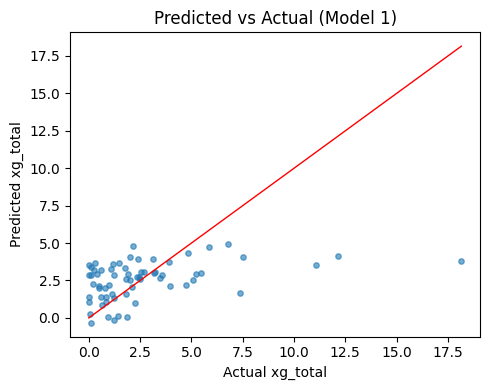

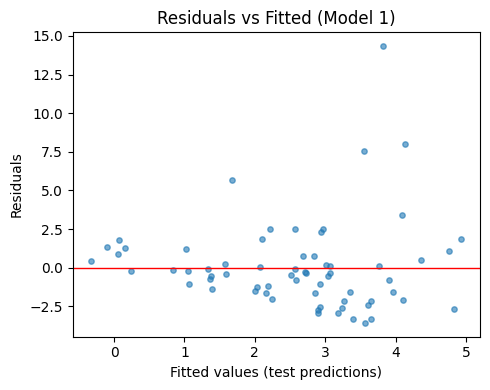


Top 2 model with features: ['minutes_played_total', 'matches_played', 'xThreat_total']
R^2 (train):  0.1985
R^2 (test):   0.1610
MSE (train):  9.5873
MSE (test):   8.3200
RMSE (train): 3.0963
RMSE (test):  2.8844


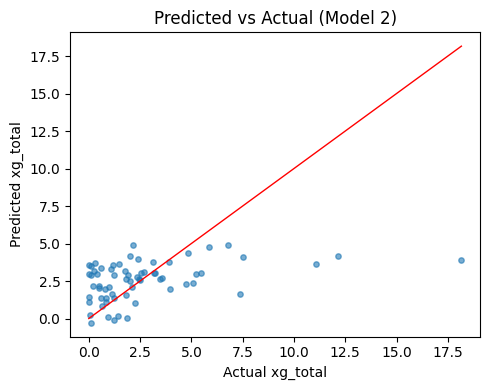

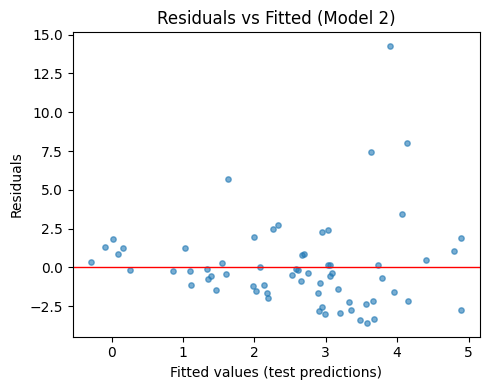


Top 3 model with features: ['minutes_played_total', 'matches_played', 'xThreat_per90']
R^2 (train):  0.1989
R^2 (test):   0.1590
MSE (train):  9.5827
MSE (test):   8.3395
RMSE (train): 3.0956
RMSE (test):  2.8878


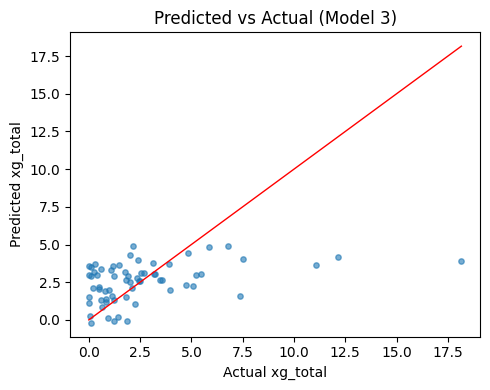

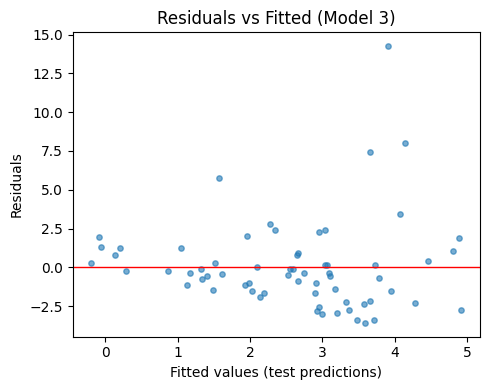

In [32]:
for i, row in top3.iterrows():
    features = row["features"]
    print(f"\n==============================")
    print(f"Top {i+1} model with features: {features}")
    print("==============================")

    res = fit_lr_on_features(subset_df, features, target_col)

    print(f"R^2 (train):  {res['r2_train']:.4f}")
    print(f"R^2 (test):   {res['r2_test']:.4f}")
    print(f"MSE (train):  {res['mse_train']:.4f}")
    print(f"MSE (test):   {res['mse_test']:.4f}")
    print(f"RMSE (train): {res['rmse_train']:.4f}")
    print(f"RMSE (test):  {res['rmse_test']:.4f}")

    y_test = res["y_test"]
    y_pred_test = res["y_pred_test"]
    residuals = y_test - y_pred_test

    # 1) Predicted vs Actual
    plt.figure(figsize=(5, 4))
    plt.scatter(y_test, y_pred_test, alpha=0.6, s=15)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()],
             color="red", linewidth=1)
    plt.xlabel("Actual xg_total")
    plt.ylabel("Predicted xg_total")
    plt.title(f"Predicted vs Actual (Model {i+1})")
    plt.tight_layout()
    plt.show()

    # 2) Residuals vs Fitted
    plt.figure(figsize=(5, 4))
    plt.scatter(y_pred_test, residuals, alpha=0.6, s=15)
    plt.axhline(0, color="red", linewidth=1)
    plt.xlabel("Fitted values (test predictions)")
    plt.ylabel("Residuals")
    plt.title(f"Residuals vs Fitted (Model {i+1})")
    plt.tight_layout()
    plt.show()
